# 04 · Taxonomic classification with Kraken 2 and Bracken

This notebook:
- Runs taxonomic classification to find which organisms the reads come from --> how many pairs belong to each species and genus. 
- Generates feature tables (one per taxonomic level).

From aftet this point onwards we stop using Euler!

We use the following:
- [Kraken 2](https://github.com/DerrickWood/kraken2) 
- [Bracken](https://github.com/jenniferlu717/Bracken) 

NOTE: Both are run through the QIIME 2 plugin `q2-annotate` (`qiime annotate classify-kraken2` and `estimate-bracken`).

**Settings:**
* As database we use PlusPF (October 2025). This is not the latest version of it but had to use this one due to large size of the 2026 version. Reference for: bacteria, archaea, viruses, human, plus protozoa and fungi. ~101 GB in memory. Still works with the Euler student account limit with a safety margin. 
* We set the confidence of Kraken 2 to 0.1, which is different from its default value of 0. So, a classification will be kept only if at least 10% of the pair's k-mers support/agree with it. We chose this to avoid false-positives.
* Bracken read length: 100bp. Not longer than most of our reads (75–151 bp).
* Unclassified reads are kept out of the feature table.

**Inputs:** the host-free reads from notebook 03 (QIIME 2 cache, keys `hostfree_reads_<batch>`), also `results/03_sample_overview.tsv`.

**Outputs** (in `results/`):
- `04_taxonomy/bracken_table_S.qza`, `bracken_taxonomy_S.qza`: species feature table and taxonomy (all 53 samples)
- `04_taxonomy/bracken_table_G.qza`, `bracken_taxonomy_G.qza`: the same at genus level
- `04_taxonomy/kraken2_reports.qza`: the Kraken 2 report of every sample 
- `04_read_tracking.tsv`: read pairs per sample at every stage, raw reads -> Bracken
- `04_classified_per_sample.png`

The Kraken 2 per-read results are large so they are kept in the QIIME 2 cache in scratch (keys `kraken2_outputs_<batch>`).

## Setup

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from qiime2 import Artifact

# Work from the repository root (this notebook is one level inside it, in notebooks/)
if Path.cwd().name == "notebooks":
    os.chdir("..")
print("Working directory:", Path.cwd())

# This makes qiime available to "!" shell commands
env_bin = str(Path(sys.executable).parent)
os.environ["PATH"] = env_bin + os.pathsep + os.environ["PATH"]

# Small outputs go to results/, large outputs stay in scratch
RESULTS = Path("results")
TAXONOMY_DIR = RESULTS / "04_taxonomy"                 # merged tables 
SCRATCH = Path("/cluster/scratch") / os.environ["USER"] / "africangut"
CACHE = SCRATCH / "qiime_cache"                         # QIIME 2 cache from notebooks 02-03
K2_DIR = SCRATCH / "04_kraken2_bracken"                 # one folder per batch

# Urbanization levels:
URBANIZATION_ORDER = ["Urban", "Peri-urban", "Peri-rural", "Hinterland"]
COLOURS = {"Urban": "#2a78d6", "Peri-urban": "#eb6834", "Peri-rural": "#1baf7a", "Hinterland": "#eda100"}
PLOT_LABELS = {"Hinterland": "Rural"}   # in plots, "Hinterland" is labelled "Rural"

# Plot style:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# Sample overview from notebook 03 (including all that came before)
overview = pd.read_csv(RESULTS / "03_sample_overview.tsv", sep="\t", index_col="sample_id")
overview["urbanization"] = pd.Categorical(overview["urbanization"], categories=URBANIZATION_ORDER)
BATCHES = sorted(overview["batch"].unique())
print("Batches:", BATCHES)

Working directory: /cluster/home/mozdemir/microbiomes
Batches: ['CMR_126', 'GNB_101', 'GNB_151', 'MDG_101', 'TZA_151']


## 1. Getting the database (run once)

This section is for importing the PlusPF database. Takes a little more than 2hrs.

In [2]:
!cat scripts/04_get_kraken2_db.sh

#!/bin/bash
#SBATCH --job-name=04_get_kraken2_db
#SBATCH --account=public
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=4
#SBATCH --mem-per-cpu=4G
#SBATCH --time=12:00:00
#SBATCH --output=logs/%x_%j.out
#SBATCH --error=logs/%x_%j.err

# Download the pre-built Kraken 2 / Bracken database "PlusPF" (build of 15 October 2025) 
# This is not the most recent version but I have to use this due to Euler's memory limit
# Gets stored in the QIIME 2 cache under two keys:
#   kraken2_db  (the Kraken 2 database: hash.k2d, opts.k2d, taxo.k2d)
#   bracken_db  (the Bracken files: database<read length>mers.kmer_distrib)
# Used by notebooks/04_taxonomy_kraken2_bracken.ipynb

set -euo pipefail

DB_NAME="k2_pluspf_20251015"
DB_URL="https://genome-idx.s3.amazonaws.com/kraken/$DB_NAME.tar.gz"
MD5_URL="https://genome-idx.s3.amazonaws.com/kraken/pluspf_20251015/pluspf.md5"
CACHE="/cluster/scratch/$USER/africangut/qiime_cache"
DB_DIR="/cluster/scratch/$USER/africangut/04_kraken2_db"
mkdir -p "$DB_DIR"
cd "$DB_DIR

In [3]:
# Submitting the database job, unless the cache already holds the database
if (CACHE / "keys" / "kraken2_db").exists() and (CACHE / "keys" / "bracken_db").exists():
    print("The database is already in the cache.")
else:
    !sbatch scripts/04_get_kraken2_db.sh

The database is already in the cache.


In [4]:
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


## 2. Test run on three samples

In [4]:
!cat scripts/04_kraken2_bracken.sh

#!/bin/bash
#SBATCH --job-name=04_kraken2_bracken
#SBATCH --account=public
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=16
#SBATCH --mem-per-cpu=8G
#SBATCH --time=24:00:00
#SBATCH --output=logs/%x_%j.out
#SBATCH --error=logs/%x_%j.err

# Used by notebooks/04_taxonomy_kraken2_bracken.ipynb (after scripts/04_get_kraken2_db.sh is run)

set -euo pipefail

BATCH="$1"
CACHE="/cluster/scratch/$USER/africangut/qiime_cache"
OUT_DIR="/cluster/scratch/$USER/africangut/04_kraken2_bracken/$BATCH"
mkdir -p "$OUT_DIR"
echo "Batch: $BATCH"

# Temporary files in scratch, deleted when the job ends
export TMPDIR="/cluster/scratch/$USER/africangut/tmp/$SLURM_JOB_ID"
mkdir -p "$TMPDIR"
trap 'rm -rf "$TMPDIR"' EXIT

# Activate the course environment 
set +eu; source ~/.bashrc; conda activate rachis-moshpit-2026.7; set -eu

# 1) Kraken 2
qiime annotate classify-kraken2 \
    --i-seqs "$CACHE:hostfree_reads_$BATCH" \
    --i-db "$CACHE:kraken2_db" \
    --p-threads 16 \
    --p-confidence 0.1 \
    --o-reports 

In [5]:
# Submittnig the test job, unless it has run already
if (K2_DIR / "test" / "kraken2_reports").exists():
    print("The test has run already.")
else:
    !sbatch --job-name=04_kraken2_bracken_test scripts/04_kraken2_bracken.sh test

The test has run already.


In [11]:
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


When the test is finished running, we investigate its results. 

Kraken 2 report --> one line per taxon. 

In [6]:
def kraken2_counts(batch):
    # Classified and unclassified read pairs per sample, from the Kraken 2 reports of one batch
    columns = ["percent", "clade_reads", "taxon_reads", "rank", "taxid", "name"]
    rows = []
    for report_file in sorted((K2_DIR / batch / "kraken2_reports").glob("*.report.txt")):
        report = pd.read_csv(report_file, sep="\t", header=None, names=columns)
        rows.append({
            "sample_id": report_file.name.replace(".report.txt", ""),   # file is <sample>.report.txt
            "kraken2_classified_pairs": report.loc[report["taxid"] == 1, "clade_reads"].sum(),
            "kraken2_unclassified_pairs": report.loc[report["taxid"] == 0, "clade_reads"].sum(),
        })
    return pd.DataFrame(rows).set_index("sample_id")


def bracken_counts(table_file):
    # Read pairs assigned by Bracken per sample (sum over all taxa of a feature table)
    table = Artifact.load(table_file).view(pd.DataFrame)       # rows: samples, columns: taxa 
    return table.sum(axis=1)


# Test samples: read pairs after host removal, classified by Kraken 2, and assigned by Bracken
test = kraken2_counts("test")
test["hostfree_read_pairs"] = overview["hostfree_read_pairs"]
test["pct_classified"] = 100 * test["kraken2_classified_pairs"] / test["hostfree_read_pairs"]
test["bracken_species_pairs"] = bracken_counts(K2_DIR / "test" / "bracken_table_S.qza")
test["pct_assigned_species"] = 100 * test["bracken_species_pairs"] / test["hostfree_read_pairs"]
test.round(1)

,kraken2_classified_pairs,kraken2_unclassified_pairs,hostfree_read_pairs,pct_classified,bracken_species_pairs,pct_assigned_species
sample_id,,,,,,
SRR13348807,7761626,3368931,11130557,69.7,7759200.0,69.7
SRR7658613,1497485,1616412,3113897,48.1,1494594.0,48.0
SRR9293007,4353393,3364831,7718224,56.4,4350896.0,56.4


Classified + unclassified add up to the host-free read pairs of each sample. A good portion of read pairs are classified.

## 3. Running all batches

Submitting one job per batch to run in parallel.

In [7]:
# Submitting one job per batch, skipping batches that have run already
for batch in BATCHES:
    if (K2_DIR / batch / "kraken2_reports").exists():
        print(batch, "has run already")
    else:
        !sbatch --job-name=04_kraken2_bracken_{batch} scripts/04_kraken2_bracken.sh {batch}

CMR_126 has run already
GNB_101 has run already
GNB_151 has run already
MDG_101 has run already
TZA_151 has run already


In [8]:
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


## 4. Merging the batches 

When all batch jobs have finished, this job merges their results a.k.a the species and genus feature tables, their taxonomies and the Kraken 2 reports. This should be a small job.

In [9]:
!cat scripts/04_merge_results.sh

#!/bin/bash
#SBATCH --job-name=04_merge_results
#SBATCH --account=public
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=1
#SBATCH --mem-per-cpu=16G
#SBATCH --time=02:00:00
#SBATCH --output=logs/%x_%j.out
#SBATCH --error=logs/%x_%j.err

# Used by notebooks/04_taxonomy_kraken2_bracken.ipynb

set -euo pipefail

BATCHES="CMR_126 GNB_101 GNB_151 MDG_101 TZA_151"
IN_DIR="/cluster/scratch/$USER/africangut/04_kraken2_bracken"
OUT_DIR="results/04_taxonomy"
mkdir -p "$OUT_DIR"

# Temporary files in scratch, deleted when the job ends
export TMPDIR="/cluster/scratch/$USER/africangut/tmp/$SLURM_JOB_ID"
mkdir -p "$TMPDIR"
trap 'rm -rf "$TMPDIR"' EXIT

# Activate the course environment
set +eu; source ~/.bashrc; conda activate rachis-moshpit-2026.7; set -eu

for LEVEL in S G; do
    # Lists of the per-batch files, e.g. ".../CMR_126/bracken_table_S.qza .../GNB_101/bracken_table_S.qza ..."
    TABLES=""; TAXONOMIES=""
    for BATCH in $BATCHES; do
        TABLES="$TABLES $IN_DIR/$BATCH/bracken_table_$LEVEL

In [10]:
# Submitting the merge job, unless the merged tables exist already
if (TAXONOMY_DIR / "bracken_table_S.qza").exists():
    print("The merged tables exist already.")
else:
    !sbatch scripts/04_merge_results.sh

Submitted batch job 17849560


In [16]:
!squeue --me

             JOBID PARTITION     NAME     USER ST       TIME  NODES NODELIST(REASON)


## 5. Reading pairs classified and assigned per sample

The last two columns of the read-tracking table. As always we flag but keep: in this step, samples whose classification rate is far below that of a typical sample: more than 20 percentage points below the median of all samples.

In [17]:
# Kraken 2: classified read pairs of all batches
kraken2 = pd.concat([kraken2_counts(batch) for batch in BATCHES])
overview["kraken2_classified_pairs"] = kraken2["kraken2_classified_pairs"]
overview["pct_classified"] = 100 * overview["kraken2_classified_pairs"] / overview["hostfree_read_pairs"]

# Bracken: read pairs assigned to a species or a genus (merged tables)
overview["bracken_species_pairs"] = bracken_counts(TAXONOMY_DIR / "bracken_table_S.qza")
overview["bracken_genus_pairs"] = bracken_counts(TAXONOMY_DIR / "bracken_table_G.qza")
overview["pct_assigned_species"] = 100 * overview["bracken_species_pairs"] / overview["hostfree_read_pairs"]

# Flag samples with a classification rate far below the typical sample
low_limit = overview["pct_classified"].median() - 20
overview["low_classified"] = overview["pct_classified"] < low_limit
print(f"Median classification rate: {overview['pct_classified'].median():.1f}%, flag below {low_limit:.1f}%")

overview[["pct_classified", "pct_assigned_species"]].describe().round(1)

Median classification rate: 50.0%, flag below 30.0%


,pct_classified,pct_assigned_species
count,53.0,53.0
mean,49.4,49.3
std,14.6,14.6
min,22.6,22.5
25%,40.8,40.8
50%,50.0,50.0
75%,59.6,59.5
max,88.3,88.3


In [18]:
# Average classification rate per batch. Batches differ in read length (101, 126, 151 bp),
# so a clear difference between them could be technical rather than biological.
overview.groupby("batch")[["read_length", "pct_classified", "pct_assigned_species"]].mean().round(1)

,read_length,pct_classified,pct_assigned_species
batch,,,
CMR_126,126.0,56.9,56.8
GNB_101,101.0,48.9,48.9
GNB_151,151.0,46.9,46.9
MDG_101,101.0,40.4,40.3
TZA_151,151.0,60.6,60.6


In [19]:
# Flagged samples
overview[overview["low_classified"]][["batch", "urbanization", "hostfree_read_pairs", "pct_classified"]]

,batch,urbanization,hostfree_read_pairs,pct_classified
sample_id,,,,
SRR9293345,CMR_126,Urban,8711158,27.787063
ERR3097515,CMR_126,Urban,8712589,27.252290
SRR7658634,MDG_101,Peri-rural,17841942,22.790098
SRR7658600,MDG_101,Peri-rural,9162733,22.581428
SRR7658592,MDG_101,Peri-rural,12751351,24.221065
SRR7658640,MDG_101,Peri-rural,72550017,25.318267
SRR7658690,MDG_101,Peri-rural,7409868,29.282681
ERR7364916,GNB_101,Hinterland,20950744,27.905935


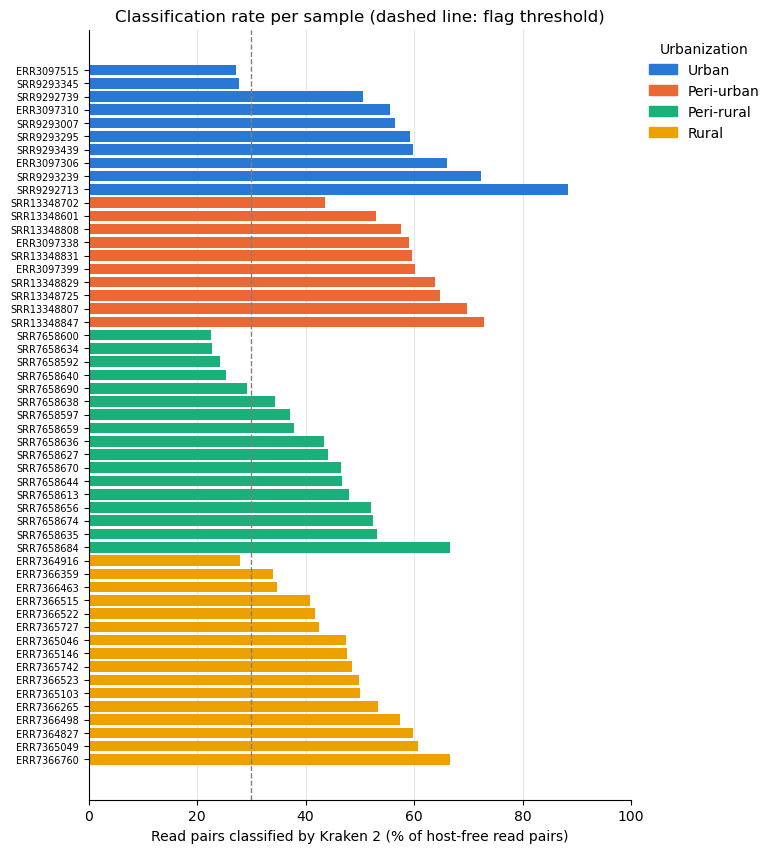

In [20]:
# Bar chart: % of host-free read pairs classified by Kraken 2, grouped and coloured by urbanization level
plot_data = overview.sort_values(["urbanization", "pct_classified"])
bar_colours = [COLOURS[level] for level in plot_data["urbanization"]]

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(plot_data.index, plot_data["pct_classified"], color=bar_colours, height=0.8)
ax.axvline(low_limit, color="grey", linestyle="--", linewidth=1)   # flag threshold
ax.invert_yaxis()                                                    # first level at the top
ax.set_xlim(0, 100)
ax.set_xlabel("Read pairs classified by Kraken 2 (% of host-free read pairs)")
ax.set_title("Classification rate per sample (dashed line: flag threshold)")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="x", color="0.9")
ax.set_axisbelow(True)
ax.legend(handles=[Patch(color=c, label=PLOT_LABELS.get(level, level)) for level, c in COLOURS.items()],
          title="Urbanization", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))

fig.savefig(RESULTS / "04_classified_per_sample.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Saving the read-tracking table

One row per sample with the read pairs after every stage (raw, after quality control, after host removal, classified by Kraken 2, assigned by Bracken at species and genus level), the percentages, and all flags from notebooks 01–04.

In [21]:
tracking = overview[[
    "country_iso3", "urbanization", "batch", "read_length",
    "raw_read_pairs", "qc_read_pairs", "hostfree_read_pairs",
    "kraken2_classified_pairs", "bracken_species_pairs", "bracken_genus_pairs",
    "pct_retained_qc", "pct_host", "pct_retained_total", "pct_classified", "pct_assigned_species",
    "low_depth", "low_retention_qc", "high_host", "low_depth_hostfree", "low_classified",
]]
tracking.to_csv(RESULTS / "04_read_tracking.tsv", sep="\t", index_label="sample_id")
tracking.head()

,country_iso3,urbanization,batch,read_length,raw_read_pairs,qc_read_pairs,hostfree_read_pairs,kraken2_classified_pairs,bracken_species_pairs,bracken_genus_pairs,pct_retained_qc,pct_host,pct_retained_total,pct_classified,pct_assigned_species,low_depth,low_retention_qc,high_host,low_depth_hostfree,low_classified
sample_id,,,,,,,,,,,,,,,,,,,,
ERR3097306,CMR,Urban,CMR_126,126,8937217,8648650,8647072,5715367,5710944.0,5713537.0,96.771176,0.018246,96.753520,66.095980,66.044830,False,False,False,False,False
SRR9292713,CMR,Urban,CMR_126,126,10252447,10090796,10090288,8913777,8911536.0,8912923.0,98.423293,0.005034,98.418339,88.340164,88.317955,False,False,False,False,False
SRR9293345,CMR,Urban,CMR_126,126,8923296,8712245,8711158,2420575,2414978.0,2418414.0,97.634831,0.012477,97.622650,27.787063,27.722813,False,False,False,False,True
SRR9292739,CMR,Urban,CMR_126,126,9012176,8892146,8891463,4494690,4491318.0,4493277.0,98.668135,0.007681,98.660557,50.550624,50.512700,False,False,False,False,False
SRR9293007,CMR,Urban,CMR_126,126,7825668,7718695,7718224,4353393,4350896.0,4352460.0,98.633050,0.006102,98.627031,56.404077,56.371725,False,False,False,False,False
